# Breast Cancer Wisconsin (Diagnostic) — Fashion-MNIST GA Fitness Adaptation

This notebook applies the **same Q-only genetic mask fitness used in the Fashion-MNIST GA-AD notebook** to the Breast Cancer Wisconsin diagnostic tabular dataset (30 numeric features; binary target: Benign / Malignant).

The dropout probability remains fixed at `p=0.3`. The GA chooses which hidden neurons remain active using a fixed-cardinality chromosome. Its fitness is the mean priority retained by active neurons:

\\[
F(m)=\\frac{\\sum_i Q_i m_i}{\\max(\\sum_i m_i,1)}.
\\]

Here, `m_i=1` means active, `m_i=0` means dropped, and `Q_i` is the combined gradient-change / derivative-descriptor priority. This is an **importance-retention heuristic**, not validation loss or a direct estimate of generalisation.

**Methodological separation:** priorities are estimated from training examples only. GA chromosome fitness uses `Q` only; validation examples are used only for epoch-level early stopping. The GA does not inspect validation predictions or labels when ranking masks.

**Models compared (same MLP 30-512-256-128-2, same optimizer, same early-stopping/LR rules, same seeds):**

| Model | Description |
|---|---|
| No Dropout | baseline |
| Std Dropout 0.3 | traditional Keras `Dropout(0.3)` after each hidden layer |
| **GA Dropout (p=0.3)** | fixed rate; Fashion-MNIST Q-only GA fitness selects active neurons |
| Random-mask (p=0.3) | control: same trainer / mask schedule, random neuron choice |

### Dataset adaptations

1. Input is 30 standardised tabular features (scaler fitted on train only), with a 2-class softmax output.
2. No official test file is supplied, so the notebook uses a stratified 60/20/20 train/validation/test split.
3. The small training partition uses `BATCH=32`; priority calibration is capped to available training examples.
4. Five random seeds are used to report mean and standard deviation.


In [1]:
import os, random, time, warnings
warnings.filterwarnings('ignore')
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
from scipy import stats
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score, f1_score, confusion_matrix, classification_report
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers, models, callbacks, optimizers
from tensorflow.keras.utils import to_categorical

# ------------------------- CONFIG -------------------------
SEEDS = [42, 7, 123, 2024, 99]   # reduce to [42] for a quick run
EPOCHS = 40
BATCH = 32                  # small dataset -> small batch (was 128 for MNIST-sized data)
LR = 1e-3
ES_PATIENCE, LR_PATIENCE = 6, 3
FIXED_P = 0.3
# (calculus adaptive-p grid / SPARSITY_REWARD removed)
GA_POP, GA_GENS = 16, 6
MASKS_PER_EPOCH = 4
ALPHA, BETA = 0.6, 0.4  # gradient-change and derivative-descriptor priority weights

DATA_PATH = '/kaggle/input/datasets/uciml/breast-cancer-wisconsin-data/data.csv'
CLASS_NAMES = ['Benign', 'Malignant']
N_CLASSES = 2

def set_seed(s):
    os.environ['PYTHONHASHSEED'] = str(s)
    random.seed(s); np.random.seed(s); tf.random.set_seed(s)

gpus = tf.config.list_physical_devices('GPU')
for g in gpus:
    try: tf.config.experimental.set_memory_growth(g, True)
    except RuntimeError as e: print(e)
print('GPUs:', len(gpus), '| TF', tf.__version__, '| Keras', keras.__version__)


GPUs: 2 | TF 2.21.0 | Keras 3.13.2


## 1. Load & inspect the Breast Cancer dataset

In [2]:
df_raw = pd.read_csv(DATA_PATH)
print('raw shape:', df_raw.shape)
# drop the id column and the empty trailing column present in this CSV
df_raw = df_raw.drop(columns=[c for c in ['id', 'Unnamed: 32'] if c in df_raw.columns])
print('shape after cleaning:', df_raw.shape)
print('missing values:', int(df_raw.isnull().sum().sum()), '| duplicate rows:', int(df_raw.duplicated().sum()))
df_raw['target'] = (df_raw['diagnosis'] == 'M').astype(int)   # 1 = Malignant, 0 = Benign
print(df_raw['target'].value_counts().sort_index().rename(dict(enumerate(CLASS_NAMES))))
display(df_raw.describe().T.head(10))

raw shape: (569, 33)
shape after cleaning: (569, 31)
missing values: 0 | duplicate rows: 0
target
Benign       357
Malignant    212
Name: count, dtype: int64


,count,mean,std,min,25%,50%,75%,max
radius_mean,569.0,14.127292,3.524049,6.98100,11.70000,13.37000,15.78000,28.11000
texture_mean,569.0,19.289649,4.301036,9.71000,16.17000,18.84000,21.80000,39.28000
perimeter_mean,569.0,91.969033,24.298981,43.79000,75.17000,86.24000,104.10000,188.50000
area_mean,569.0,654.889104,351.914129,143.50000,420.30000,551.10000,782.70000,2501.00000
smoothness_mean,569.0,0.096360,0.014064,0.05263,0.08637,0.09587,0.10530,0.16340
compactness_mean,569.0,0.104341,0.052813,0.01938,0.06492,0.09263,0.13040,0.34540
concavity_mean,569.0,0.088799,0.079720,0.00000,0.02956,0.06154,0.13070,0.42680
concave points_mean,569.0,0.048919,0.038803,0.00000,0.02031,0.03350,0.07400,0.20120
symmetry_mean,569.0,0.181162,0.027414,0.10600,0.16190,0.17920,0.19570,0.30400
fractal_dimension_mean,569.0,0.062798,0.007060,0.04996,0.05770,0.06154,0.06612,0.09744


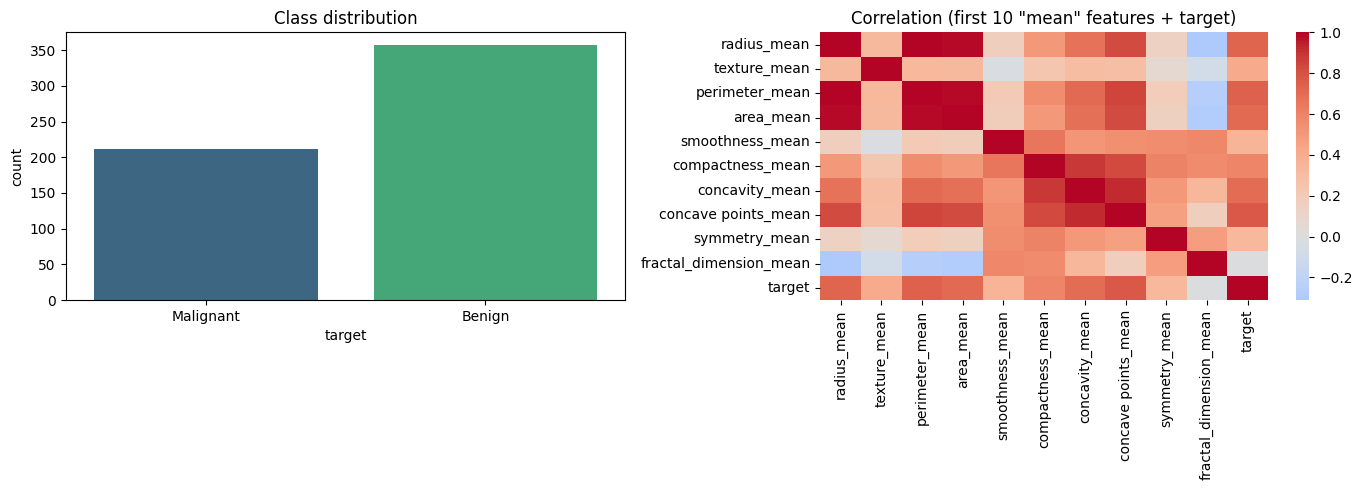

In [3]:
FEATURES = [c for c in df_raw.columns if c not in ('diagnosis', 'target')]
fig, ax = plt.subplots(1, 2, figsize=(14, 5))
sns.countplot(x=df_raw['target'].map(dict(enumerate(CLASS_NAMES))), ax=ax[0], palette='viridis')
ax[0].set_title('Class distribution')
sns.heatmap(df_raw[FEATURES[:10] + ['target']].corr(), cmap='coolwarm', center=0, ax=ax[1])
ax[1].set_title('Correlation (first 10 "mean" features + target)')
plt.tight_layout(); plt.show()

## 2. Preprocessing & splits (60% train / 20% val / 20% test, stratified; scaler fitted on train only)

In [4]:
X_all = df_raw[FEATURES].values.astype('float32')
y_all = df_raw['target'].values

X_tmp, X_test, y_tmp, y_test_int = train_test_split(X_all, y_all, test_size=0.20, random_state=42, stratify=y_all)
X_train, X_val, y_train_int, y_val_int = train_test_split(X_tmp, y_tmp, test_size=0.25, random_state=42, stratify=y_tmp)

scaler = StandardScaler().fit(X_train)
X_train, X_val, X_test = [scaler.transform(a).astype('float32') for a in (X_train, X_val, X_test)]
N_FEATURES = X_train.shape[1]
y_train, y_val, y_test = [to_categorical(a, N_CLASSES) for a in (y_train_int, y_val_int, y_test_int)]
print('train', X_train.shape, 'val', X_val.shape, 'test', X_test.shape)

train (341, 30) val (114, 30) test (114, 30)


## 3. Shared architecture, baselines (No Dropout, Standard Dropout)

In [5]:
LAYER_NAMES = ['dense_512', 'dense_256', 'dense_128']
LAYER_SIZES = {'dense_512': 512, 'dense_256': 256, 'dense_128': 128}

def build_mlp(name, dropout=0.0):
    m = models.Sequential(name='mlp')
    m.add(layers.Input(shape=(N_FEATURES,)))
    for u, n in zip((512, 256, 128), LAYER_NAMES):
        m.add(layers.Dense(u, activation='relu', kernel_initializer='he_normal', name=n))
        if dropout > 0: m.add(layers.Dropout(dropout))
    m.add(layers.Dense(N_CLASSES, activation='softmax', name='output'))
    return m

def get_callbacks():
    return [callbacks.EarlyStopping(monitor='val_loss', patience=ES_PATIENCE, restore_best_weights=True, verbose=0),
            callbacks.ReduceLROnPlateau(monitor='val_loss', factor=0.5, patience=LR_PATIENCE, min_lr=1e-6, verbose=0)]

N_TRAIN_EVAL = min(10000, len(X_train))   # un-masked train subset used to measure the generalisation gap
def run_keras(kind, seed):
    set_seed(seed)
    model = build_mlp(kind, FIXED_P if kind == 'Std Dropout 0.3' else 0.0)
    model.compile(optimizer=optimizers.Adam(LR, name='adam'), loss='categorical_crossentropy', metrics=['accuracy'])
    t0 = time.time()
    h = model.fit(X_train, y_train, validation_data=(X_val, y_val), epochs=EPOCHS,
                  batch_size=BATCH, callbacks=get_callbacks(), verbose=0)
    el = time.time() - t0
    return dict(history=h.history, time=el, epochs=len(h.history['loss']),
                p_hist=None, active=None,
                prob_test=model.predict(X_test, verbose=0, batch_size=2048),
                prob_train=model.predict(X_train[:N_TRAIN_EVAL], verbose=0, batch_size=2048))

## 4. GA Dropout modules

* **A – Gradient tracker:** EMA of the batch-mean activation gradient ∂L/∂h per neuron; `s_i` = min-max-normalised |ΔEMA|.
* **B – Polynomial derivative descriptor:** `P(x)=Σ x^(10 s_i)`; `C_i = Σ_k w_k |(a_i)_k · c^(a_i−k)|` with `c=1`, `K=2`, then min-max normalised.
* **C – Priority:** `Q_i = α s_i + β Ĉ_i`. High Q ⇒ neuron is *kept*; the GA drops low-Q neurons preferentially.
* **D – Fixed-cardinality GA:** exactly `D = round(N · p)` inactive neurons per layer (p is a fixed hyper-parameter, e.g. 0.3). The calculus-based adaptive rate selection has been removed.


In [6]:
class GradientTracker:
    def __init__(self, sizes, rho=0.9, eps=1e-8):
        self.rho, self.eps = rho, eps
        self.ema = {n: None for n in sizes}; self.delta = {n: np.zeros(s) for n, s in sizes.items()}
    def update(self, grads):
        for n, g in grads.items():
            g = np.asarray(g, dtype=np.float64)
            if self.ema[n] is None:
                self.ema[n] = g.copy(); self.delta[n] = np.zeros_like(g)
            else:
                prev = self.ema[n]; self.ema[n] = self.rho * prev + (1 - self.rho) * g
                self.delta[n] = np.abs(self.ema[n] - prev)
    def scores(self, n):
        d = self.delta[n]; lo, hi = d.min(), d.max()
        return np.full_like(d, 0.5) if hi - lo < self.eps else (d - lo) / (hi - lo + self.eps)

def derivative_descriptor(s, K=2, weights=None, eps=1e-8):
    w = np.ones(K) / K if weights is None else np.asarray(weights)
    a = 10.0 * np.asarray(s, dtype=np.float64)
    C = np.zeros_like(a)
    for k in range(1, K + 1):
        ff = np.ones_like(a)
        for j in range(k): ff = ff * (a - j)        # falling factorial (a)_k ; c=1 so c^(a-k)=1
        C += w[k - 1] * np.abs(ff)
    lo, hi = C.min(), C.max()
    return np.full_like(C, 0.5) if hi - lo < eps else (C - lo) / (hi - lo + eps)

class GeneticMaskOptimizer:
    """Fashion-MNIST GA: fixed-cardinality masks with Q-only retained-importance fitness."""
    def __init__(self, N, D_star, Q, population_size=GA_POP, generations=GA_GENS,
                 mutation_rate=0.04, elite_frac=0.25, rng=None):
        self.N, self.D, self.A = N, D_star, N - D_star
        self.Q = np.asarray(Q, dtype=np.float64)
        self.pop_size, self.generations = population_size, generations
        self.mutation_rate = mutation_rate
        self.n_elite = max(2, int(elite_frac * population_size))
        self.rng = rng if rng is not None else np.random.RandomState(0)

    def _random_mask(self):
        mask = np.zeros(self.N, dtype=np.int8)
        mask[self.rng.choice(self.N, self.A, replace=False)] = 1
        return mask

    def _repair(self, mask):
        mask = mask.copy()
        active, inactive = np.where(mask == 1)[0], np.where(mask == 0)[0]
        if len(active) > self.A:
            remove = active[np.argsort(self.Q[active])[:len(active) - self.A]]
            mask[remove] = 0
        elif len(active) < self.A:
            add = inactive[np.argsort(-self.Q[inactive])[:self.A - len(active)]]
            mask[add] = 1
        return mask

    def _fitness(self, mask):
        return float(np.sum(self.Q * mask) / max(self.A, 1))

    def evolve(self):
        population = np.asarray([self._random_mask() for _ in range(self.pop_size)])
        for _ in range(self.generations):
            fitness = np.asarray([self._fitness(m) for m in population])
            elite = population[np.argsort(-fitness)[:self.n_elite]].copy()
            next_population = list(elite)
            while len(next_population) < self.pop_size:
                parent_a = elite[self.rng.randint(len(elite))]
                parent_b = elite[self.rng.randint(len(elite))]
                child = np.where(self.rng.rand(self.N) < 0.5,
                                 parent_a, parent_b).astype(np.int8)
                flip = self.rng.rand(self.N) < self.mutation_rate
                child[flip] = 1 - child[flip]
                next_population.append(self._repair(child))
            population = np.asarray(next_population)

        fitness = np.asarray([self._fitness(m) for m in population])
        unique_elites = []
        for idx in np.argsort(-fitness):
            candidate = population[idx]
            if not any(np.array_equal(candidate, old) for old in unique_elites):
                unique_elites.append(candidate.copy())
            if len(unique_elites) >= self.n_elite:
                break
        return np.asarray(unique_elites, dtype=np.float32)

## 5. GA Dropout trainer (Random-mask control)

Dropout rate is fixed (`FIXED_P`). The genetic algorithm only decides which neurons are active. It uses the **Fashion-MNIST GA fitness**:

\\[
F(m)=\\frac{\\sum_i Q_i m_i}{\\max(\\sum_i m_i,1)}.
\\]

The GA uses fixed-cardinality masks, uniform gene-wise crossover, mutation followed by repair, elitism, and unique elite-mask retention. It does **not** score candidates using validation loss, a validation-derived reward, or a mask-stability penalty. Validation data are reserved for epoch-level early stopping.


In [7]:
def cce(y, p):
    return float(-np.mean(np.sum(y * np.log(np.clip(p, 1e-9, 1.0)), axis=1)))

class GACIADTrainer:
    """GA-informed dropout with *fixed* rate p. No calculus-based adaptive p*."""
    def __init__(self, seed, mask_mode='ga', fixed_p=FIXED_P):
        set_seed(seed)
        self.seed, self.mask_mode, self.fixed_p = seed, mask_mode, fixed_p
        self.rng = np.random.RandomState(seed)
        self.model = build_mlp('GACIAD')
        self.L = {n: self.model.get_layer(n) for n in LAYER_NAMES + ['output']}
        self.opt = optimizers.Adam(LR); self.opt.build(self.model.trainable_variables)
        self.loss_fn = keras.losses.CategoricalCrossentropy()
        self.tracker = GradientTracker(LAYER_SIZES)
        self.masks = {n: np.ones(s, np.float32) for n, s in LAYER_SIZES.items()}
        self.mask_vars = {n: tf.Variable(np.ones(s, np.float32), trainable=False) for n, s in LAYER_SIZES.items()}
        self.scale_vars = {n: tf.Variable(1.0, trainable=False) for n in LAYER_SIZES}
        self.Q = {n: np.ones(s) for n, s in LAYER_SIZES.items()}
        self.p_now = fixed_p
        self.train_step = tf.function(self._train_step)

    # ---- forward passes -------------------------------------------------
    def forward(self, x, masks=None):
        h = x
        for n in LAYER_NAMES:
            h = self.L[n](h)
            if masks is not None:
                m = masks[n]; keep = max(float(np.mean(m)), 1e-6)
                h = h * tf.constant(m, tf.float32) / keep            # inverted dropout
        return self.L['output'](h)

    def _train_step(self, x, y):
        with tf.GradientTape() as tape:
            h = x
            for n in LAYER_NAMES:
                h = self.L[n](h) * self.mask_vars[n] * self.scale_vars[n]
            loss = self.loss_fn(y, self.L['output'](h))
        g = tape.gradient(loss, self.model.trainable_variables)
        self.opt.apply_gradients(zip(g, self.model.trainable_variables))
        return loss

    def predict(self, X):
        out = [self.forward(tf.constant(X[i:i + 2048])).numpy() for i in range(0, len(X), 2048)]
        return np.concatenate(out)

    # ---- Module A/B/C: activation gradients -> priorities ----------------
    def _activation_grads(self, xb, yb):
        with tf.GradientTape(persistent=True) as tape:
            h, acts = xb, []
            for n in LAYER_NAMES:
                h = self.L[n](h); acts.append(h)
            loss = self.loss_fn(yb, self.L['output'](h))
        gs = [tape.gradient(loss, a) for a in acts]; del tape
        return {n: np.mean(np.abs(g.numpy()), axis=0) for n, g in zip(LAYER_NAMES, gs)}

    def _update_priorities(self, Xc, yc, n_batches=6):
        acc = {n: np.zeros(s) for n, s in LAYER_SIZES.items()}; cnt = 0
        for i in range(0, len(Xc), BATCH):
            g = self._activation_grads(Xc[i:i + BATCH], yc[i:i + BATCH])
            for n in acc: acc[n] += g[n]
            cnt += 1
            if cnt >= n_batches: break
        self.tracker.update({n: acc[n] / cnt for n in acc})
        for n in LAYER_NAMES:
            s = self.tracker.scores(n); self.Q[n] = ALPHA * s + BETA * derivative_descriptor(s)

    # ---- Module E: mask selection (fixed p, Q-only GA or random) --------
    def _refresh_masks(self, Xc, yc):
        """Refresh masks using training-only priorities and Fashion-MNIST GA fitness.

        F(m) = sum_i(Q_i * m_i) / max(sum_i(m_i), 1).
        Validation data are excluded from chromosome fitness.
        """
        if self.mask_mode == 'ga':
            self._update_priorities(Xc, yc)

        cur = {n: m.copy() for n, m in self.masks.items()}
        for n, size in LAYER_SIZES.items():
            D = min(int(round(size * self.fixed_p)), size - 1)
            if D == 0:
                cur[n] = np.ones(size, np.float32)
            elif self.mask_mode == 'random':
                cur[n] = self._random_masks_layer(size, D)
            else:
                ga = GeneticMaskOptimizer(
                    size, D, self.Q[n],
                    population_size=GA_POP,
                    generations=GA_GENS,
                    mutation_rate=0.04,
                    elite_frac=0.25,
                    rng=self.rng
                )
                elite_masks = ga.evolve()
                # Resample among unique high-fitness masks, as in Fashion-MNIST GA-AD.
                chosen = self.rng.randint(len(elite_masks))
                cur[n] = elite_masks[chosen].astype(np.float32)

        self.masks = cur
        for n in LAYER_NAMES:
            self.mask_vars[n].assign(cur[n])
            self.scale_vars[n].assign(1.0 / max(float(cur[n].mean()), 1e-6))

    def _random_masks_layer(self, size, D):
        m = np.ones(size, np.float32)
        m[self.rng.choice(size, D, replace=False)] = 0
        return m

    # ---- training loop ---------------------------------------------------
    def fit(self, Xtr, ytr, Xval, yval):
        rng = self.rng
        # subsample sizes capped to the (small) dataset
        ci = rng.choice(len(Xtr), min(2048, len(Xtr)), replace=False)
        Xc, yc = tf.constant(Xtr[ci]), tf.constant(ytr[ci])
        vi = rng.choice(len(Xval), min(1024, len(Xval)), replace=False)
        Xvs, yvs = tf.constant(Xval[vi]), tf.constant(yval[vi])
        steps = len(Xtr) // BATCH; seg = max(steps // MASKS_PER_EPOCH, 1)
        hist = {k: [] for k in ['loss', 'val_loss', 'accuracy', 'val_accuracy', 'p_star', 'active']}
        best, best_w, wait, lr_wait, lr = np.inf, None, 0, 0, LR
        for ep in range(EPOCHS):
            perm = rng.permutation(len(Xtr)); losses, ps = [], []
            for sg in range(MASKS_PER_EPOCH):
                self._refresh_masks(Xc, yc); ps.append(self.p_now)
                for st in range(seg):
                    idx = perm[(sg * seg + st) * BATCH:(sg * seg + st + 1) * BATCH]
                    if len(idx) == 0: continue
                    losses.append(self.train_step(tf.constant(Xtr[idx]), tf.constant(ytr[idx])))
            pv = self.predict(Xval); vl = cce(yval, pv); va = float(np.mean(pv.argmax(1) == yval.argmax(1)))
            ptr = self.predict(Xtr[:5000])
            hist['loss'].append(float(np.mean([float(l) for l in losses]))); hist['val_loss'].append(vl)
            hist['accuracy'].append(float(np.mean(ptr.argmax(1) == ytr[:5000].argmax(1)))); hist['val_accuracy'].append(va)
            hist['p_star'].append(float(np.mean(ps))); hist['active'].append(float(np.mean([m.mean() for m in self.masks.values()])))
            # early stopping + ReduceLROnPlateau (identical rules to the Keras baselines)
            if vl < best - 1e-7:
                best, best_w, wait, lr_wait = vl, self.model.get_weights(), 0, 0
            else:
                wait += 1; lr_wait += 1
                if lr_wait >= LR_PATIENCE:
                    lr = max(lr * 0.5, 1e-6); self.opt.learning_rate.assign(lr); lr_wait = 0
                if wait >= ES_PATIENCE: break
        if best_w is not None: self.model.set_weights(best_w)
        return hist

def run_custom(kind, seed):
    cfg = {
        'GA Dropout (p=0.3)': dict(mask_mode='ga'),
        'Random-mask (p=0.3)': dict(mask_mode='random'),
    }[kind]
    tr = GACIADTrainer(seed, **cfg)
    t0 = time.time(); h = tr.fit(X_train, y_train, X_val, y_val); el = time.time() - t0
    return dict(history=h, time=el, epochs=len(h['loss']), p_hist=h['p_star'], active=h['active'],
                prob_test=tr.predict(X_test), prob_train=tr.predict(X_train[:N_TRAIN_EVAL]))


## 6. Run the full experiment (all models × all seeds)


In [8]:
MODELS = ['No Dropout', 'Std Dropout 0.3', 'GA Dropout (p=0.3)', 'Random-mask (p=0.3)']
RUNS, rows = {}, []
for seed in SEEDS:
    for m in MODELS:
        r = run_keras(m, seed) if m in ('No Dropout', 'Std Dropout 0.3') else run_custom(m, seed)
        RUNS[(m, seed)] = r
        yp = r['prob_test'].argmax(1); ytr_p = r['prob_train'].argmax(1)
        acc = accuracy_score(y_test_int, yp); tr_acc = accuracy_score(y_train_int[:N_TRAIN_EVAL], ytr_p)
        rows.append({'Model': m, 'Seed': seed, 'Test Acc': acc, 'Macro F1': f1_score(y_test_int, yp, average='macro'),
                     'Test Loss': cce(y_test, r['prob_test']), 'Train Acc (no mask)': tr_acc,
                     'Gen. Gap (train-test)': tr_acc - acc, 'Epochs': r['epochs'], 'Time (s)': r['time']})
        print(f"seed {seed:>4} | {m:<25} | test acc {acc:.4f} | gap {tr_acc-acc:+.4f} | epochs {r['epochs']:>2} | {r['time']:.0f}s")
df = pd.DataFrame(rows)


seed   42 | No Dropout                | test acc 0.9649 | gap +0.0263 | epochs  8 | 7s
seed   42 | Std Dropout 0.3           | test acc 0.9825 | gap +0.0117 | epochs 14 | 8s
seed   42 | GA Dropout (p=0.3)        | test acc 0.9825 | gap +0.0029 | epochs 20 | 14s
seed   42 | Random-mask (p=0.3)       | test acc 0.9737 | gap +0.0146 | epochs 11 | 1s
seed    7 | No Dropout                | test acc 0.9737 | gap +0.0205 | epochs 10 | 5s
seed    7 | Std Dropout 0.3           | test acc 0.9825 | gap +0.0117 | epochs 16 | 8s
seed    7 | GA Dropout (p=0.3)        | test acc 0.9561 | gap +0.0233 | epochs  9 | 6s
seed    7 | Random-mask (p=0.3)       | test acc 0.9825 | gap +0.0087 | epochs 20 | 1s
seed  123 | No Dropout                | test acc 0.9737 | gap +0.0234 | epochs 10 | 4s
seed  123 | Std Dropout 0.3           | test acc 0.9737 | gap +0.0234 | epochs 18 | 8s
seed  123 | GA Dropout (p=0.3)        | test acc 0.9825 | gap +0.0058 | epochs 13 | 8s
seed  123 | Random-mask (p=0.3)       | te

## 7. Aggregate results (mean ± std over seeds)

,Test Acc,Macro F1,Test Loss,Gen. Gap (train-test),Epochs,Time (s)
No Dropout,0.9649 ± 0.0088,0.9621 ± 0.0095,0.1325 ± 0.0332,0.0316 ± 0.0114,10.4 ± 1.7,5.1 ± 1.0
Std Dropout 0.3,0.9789 ± 0.0048,0.9772 ± 0.0053,0.0914 ± 0.0138,0.0152 ± 0.0063,16.2 ± 1.8,7.8 ± 0.3
GA Dropout (p=0.3),0.9772 ± 0.0118,0.9752 ± 0.0129,0.0833 ± 0.0086,0.0099 ± 0.0089,14.6 ± 6.1,9.5 ± 4.1
Random-mask (p=0.3),0.9737 ± 0.0062,0.9715 ± 0.0067,0.0874 ± 0.0150,0.0163 ± 0.0057,16.2 ± 5.5,1.0 ± 0.2


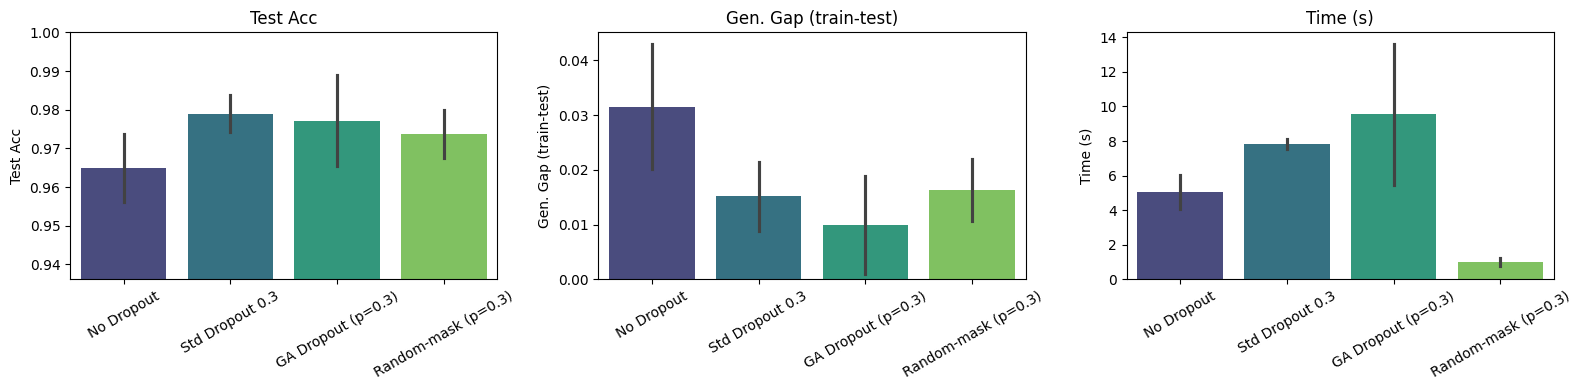

In [9]:
agg = df.groupby('Model').agg(['mean', 'std']).loc[MODELS]
cols = ['Test Acc', 'Macro F1', 'Test Loss', 'Gen. Gap (train-test)', 'Epochs', 'Time (s)']
summary = pd.DataFrame({c: [f"{agg[(c,'mean')][m]:.4f} ± {np.nan_to_num(agg[(c,'std')][m]):.4f}" if c not in ('Epochs','Time (s)')
                            else f"{agg[(c,'mean')][m]:.1f} ± {np.nan_to_num(agg[(c,'std')][m]):.1f}" for m in MODELS] for c in cols}, index=MODELS)
display(summary)

fig, ax = plt.subplots(1, 3, figsize=(16, 4))
for a, c in zip(ax, ['Test Acc', 'Gen. Gap (train-test)', 'Time (s)']):
    sns.barplot(data=df, x='Model', y=c, order=MODELS, ax=a, errorbar='sd', palette='viridis')
    a.set_title(c); a.set_xlabel(''); a.tick_params(axis='x', rotation=30)
    if c == 'Test Acc': a.set_ylim(max(df['Test Acc'].min() - 0.02, 0), min(df['Test Acc'].max() + 0.02, 1.0))
plt.tight_layout(); plt.show()

## 8. Learning curves & active-neuron fraction


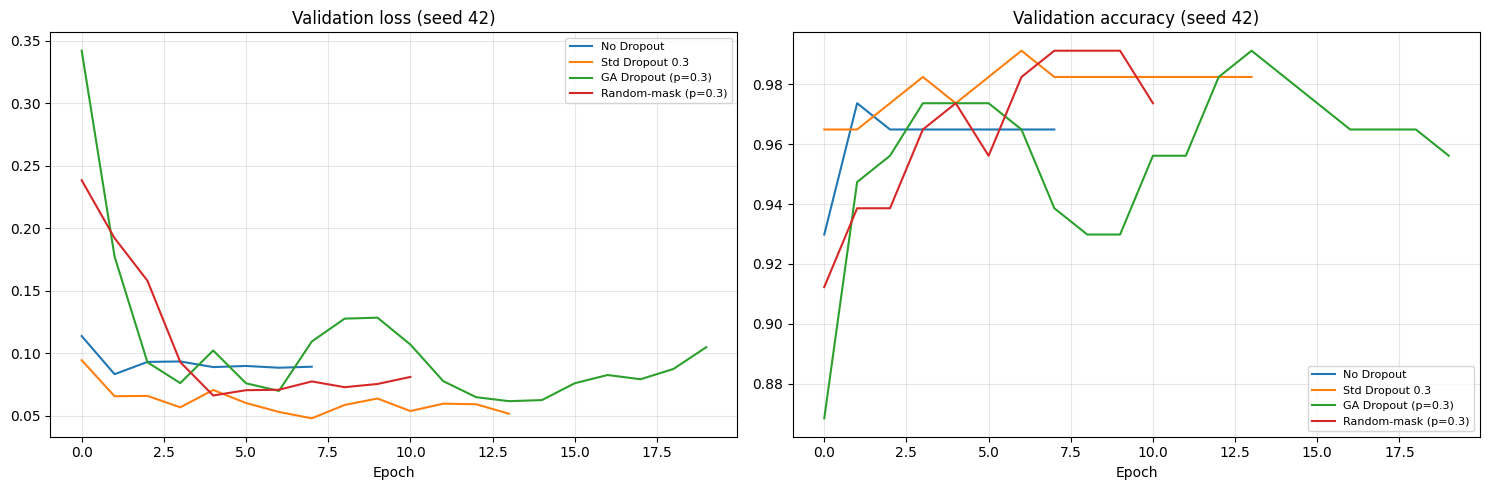

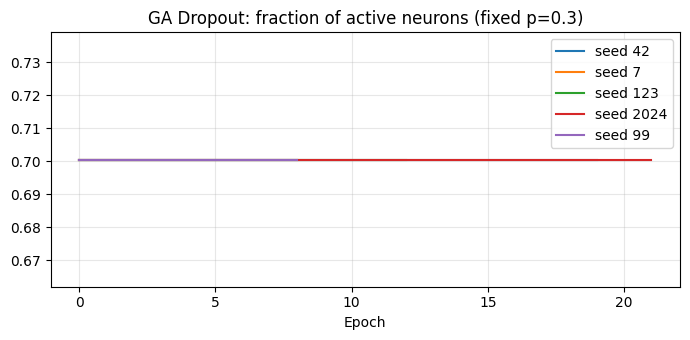

In [10]:
s0 = SEEDS[0]
fig, ax = plt.subplots(1, 2, figsize=(15, 5))
for m in MODELS:
    h = RUNS[(m, s0)]['history']
    ax[0].plot(h['val_loss'], label=m); ax[1].plot(h['val_accuracy'], label=m)
ax[0].set_title(f'Validation loss (seed {s0})'); ax[1].set_title(f'Validation accuracy (seed {s0})')
for a in ax: a.set_xlabel('Epoch'); a.grid(alpha=.3); a.legend(fontsize=8)
plt.tight_layout(); plt.show()

fig, ax = plt.subplots(1, 1, figsize=(7, 3.5))
for sd in SEEDS:
    r = RUNS[('GA Dropout (p=0.3)', sd)]
    ax.plot(r['active'], label=f'seed {sd}')
ax.set_title('GA Dropout: fraction of active neurons (fixed p=0.3)')
ax.set_xlabel('Epoch'); ax.grid(alpha=.3); ax.legend()
plt.tight_layout(); plt.show()


## 9. Per-class behaviour (seed-averaged F1) and confusion matrices

,No Dropout,Std Dropout 0.3,GA Dropout (p=0.3),Random-mask (p=0.3)
Benign,0.9725,0.9835,0.9822,0.9794
Malignant,0.9517,0.9708,0.9681,0.9635


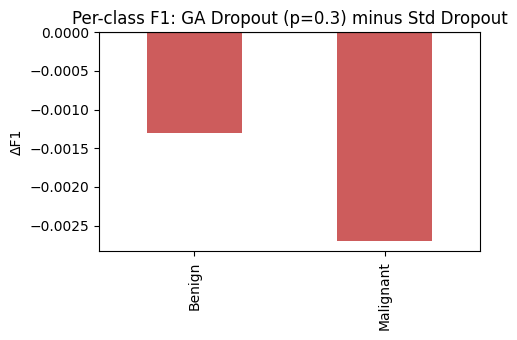

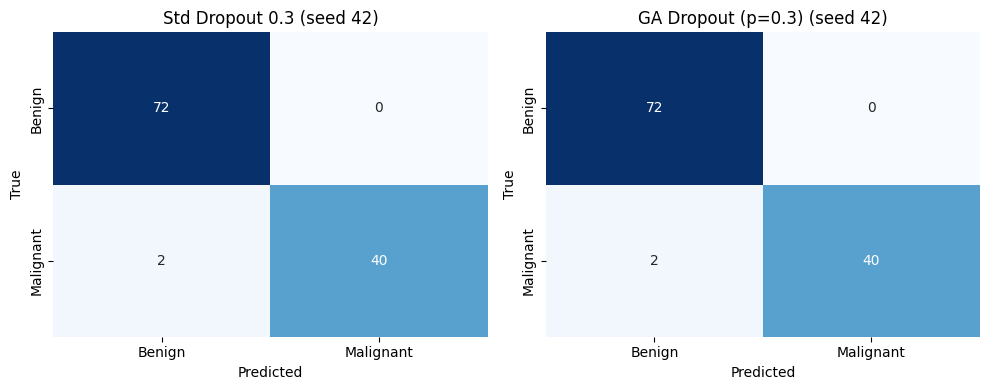

              precision    recall  f1-score   support

      Benign       0.97      1.00      0.99        72
   Malignant       1.00      0.95      0.98        42

    accuracy                           0.98       114
   macro avg       0.99      0.98      0.98       114
weighted avg       0.98      0.98      0.98       114



In [11]:
def per_class_f1(m):
    return np.mean([f1_score(y_test_int, RUNS[(m, s)]['prob_test'].argmax(1), average=None) for s in SEEDS], axis=0)

pc = pd.DataFrame({m: per_class_f1(m) for m in MODELS}, index=CLASS_NAMES).round(4)
display(pc)

diff = (pc['GA Dropout (p=0.3)'] - pc['Std Dropout 0.3'])
plt.figure(figsize=(5, 3.5))
diff.plot(kind='bar', color=np.where(diff >= 0, 'seagreen', 'indianred'))
plt.axhline(0, c='k', lw=.8)
plt.title('Per-class F1: GA Dropout (p=0.3) minus Std Dropout')
plt.ylabel('ΔF1')
plt.tight_layout()
plt.show()

fig, ax = plt.subplots(1, 2, figsize=(10, 4))
for a, m in zip(ax, ['Std Dropout 0.3', 'GA Dropout (p=0.3)']):
    cm = confusion_matrix(y_test_int, RUNS[(m, s0)]['prob_test'].argmax(1))
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
                xticklabels=CLASS_NAMES, yticklabels=CLASS_NAMES, ax=a, cbar=False)
    a.set_title(f'{m} (seed {s0})')
    a.set_xlabel('Predicted')
    a.set_ylabel('True')
plt.tight_layout()
plt.show()

print(classification_report(
    y_test_int,
    RUNS[('GA Dropout (p=0.3)', s0)]['prob_test'].argmax(1),
    target_names=CLASS_NAMES
))

## 10. Statistical comparison & automatic verdict


In [12]:
def pair(a, b, metric='Test Acc'):
    xa = df[df.Model == a].sort_values('Seed')[metric].values
    xb = df[df.Model == b].sort_values('Seed')[metric].values
    d = xa.mean() - xb.mean()
    p = stats.ttest_rel(xa, xb).pvalue if len(xa) > 1 else np.nan
    return d, p

pairs = [('GA Dropout (p=0.3)', 'Std Dropout 0.3'),
         ('GA Dropout (p=0.3)', 'No Dropout'),
         ('GA Dropout (p=0.3)', 'Random-mask (p=0.3)'),
         ('Std Dropout 0.3', 'No Dropout')]
tab = pd.DataFrame([{'A': a, 'B': b, 'Δ Test Acc (A-B)': pair(a, b)[0], 'paired t p-value': pair(a, b)[1],
                     'Δ Gen. gap (A-B)': pair(a, b, 'Gen. Gap (train-test)')[0],
                     'Time ratio A/B': df[df.Model == a]['Time (s)'].mean() / df[df.Model == b]['Time (s)'].mean()}
                    for a, b in pairs]).round(4)
display(tab)

means = df.groupby('Model')['Test Acc'].mean().loc[MODELS]
best = means.idxmax()
d, p = pair('GA Dropout (p=0.3)', 'Std Dropout 0.3')
t_ratio = df[df.Model == 'GA Dropout (p=0.3)']['Time (s)'].mean() / df[df.Model == 'Std Dropout 0.3']['Time (s)'].mean()
print('=' * 78)
print(f'Highest mean test accuracy : {best} ({means[best]:.4f})')
print(f'GA Dropout vs Std Dropout 0.3 : Δacc = {d:+.4f}  (paired t-test p = {p:.3f}, n = {len(SEEDS)} seeds)')
if np.isnan(p) or p >= 0.05:
    verdict = 'NO statistically reliable accuracy difference'
elif d > 0:
    verdict = 'GA Dropout is significantly BETTER in accuracy'
else:
    verdict = 'Traditional dropout is significantly BETTER in accuracy'
print('Accuracy verdict :', verdict)
print(f'Compute cost     : GA Dropout needs {t_ratio:.1f}x the wall-clock time of Std Dropout')
gg = df.groupby('Model')['Gen. Gap (train-test)'].mean()
print(f"Generalisation gap (train-test): Std {gg['Std Dropout 0.3']:.4f} | GA {gg['GA Dropout (p=0.3)']:.4f} | None {gg['No Dropout']:.4f}")
ga_vs_rand = pair('GA Dropout (p=0.3)', 'Random-mask (p=0.3)')
print(f'GA neuron choice vs random neuron choice (same p): Δacc = {ga_vs_rand[0]:+.4f} (p = {ga_vs_rand[1]:.3f})')
print('=' * 78)


,A,B,Δ Test Acc (A-B),paired t p-value,Δ Gen. gap (A-B),Time ratio A/B
0,GA Dropout (p=0.3),Std Dropout 0.3,-0.0018,0.7990,-0.0053,1.2186
1,GA Dropout (p=0.3),No Dropout,0.0123,0.2056,-0.0217,1.8883
2,GA Dropout (p=0.3),Random-mask (p=0.3),0.0035,0.6702,-0.0064,9.3840
3,Std Dropout 0.3,No Dropout,0.0140,0.0349,-0.0164,1.5497


Highest mean test accuracy : Std Dropout 0.3 (0.9789)
GA Dropout vs Std Dropout 0.3 : Δacc = -0.0018  (paired t-test p = 0.799, n = 5 seeds)
Accuracy verdict : NO statistically reliable accuracy difference
Compute cost     : GA Dropout needs 1.2x the wall-clock time of Std Dropout
Generalisation gap (train-test): Std 0.0152 | GA 0.0099 | None 0.0316
GA neuron choice vs random neuron choice (same p): Δacc = +0.0035 (p = 0.670)


## 11. How to read the results

1. **Accuracy / generalisation:** compare `Test Acc` and `Gen. Gap` for *Std Dropout 0.3* vs *GA Dropout (p=0.3)*; the verdict cell reports whether the difference is statistically reliable.
2. **Does the GA / priority score matter?** Compare *GA Dropout (p=0.3)* with *Random-mask (p=0.3)*.
3. **Overhead:** `Time (s)` ratio (GA is more expensive because of priority tracking + evolutionary search each mask segment).

**Note:** Calculus-based adaptive \(p^*\) has been removed; rate is fixed at 0.3 for both GA and random-mask runs.

**Caveats specific to this dataset:** the test set has only 114 patients, so one misclassification ≈ 0.9 % accuracy; differences below ~1–2 % are within noise. GA fitness is evaluated on the validation set (also used for early stopping), which can add a small selection bias to validation metrics (the test set is untouched). Because the dataset is tiny, a 512-256-128 MLP is heavily over-parameterised, which is exactly where dropout-type regularisers are expected to matter.


### GA fitness implementation note

The GA fitness matches the Fashion-MNIST GA-AD implementation: `sum(Q * mask) / active_count`. Because each chromosome has exactly `N - D` active genes, the denominator is constant within a layer. `Q` is computed from training-only activation-gradient statistics and the derivative descriptor. Validation loss is not part of genetic fitness; it is used only by the outer training loop for early stopping.
